In [ ]:
import numpy as np
import pandas as pd
pd.set_option('display.max_rows', None)

# Limites Regulatórios para o PLD fixados pela ANEEL

In [46]:
# PLD limites regulatórios ANEEL
data = {
    'year':      [2003,   2004,   2005,   2006,   2007,   2008,   2009,   2010,   2011,   2012,   2013,   2014,   2015,   2016,   2017,   2018,   2019,   2020,   2021,   2022,   2023,   2024,   2025,   2026],
    'pld_min':   [16.95,  18.59,  18.33,  16.92,  17.59,  15.47,  16.31,  12.80,  12.08,  12.20,  14.13,  15.62,  30.26,  30.25,  33.68,  40.16,  42.35,  39.68,  49.77,  55.70,  69.04,  61.07,  58.60,  57.31],
    'pld_max':   [350.00, 452.00, 507.28, 515.80, 534.30, 569.59, 633.37, 622.21, 689.18, 757.52, 780.03, 822.83, 388.83, 422.56, 533.82, 505.18, 513.89, 559.75, 583.88, 646.58, 684.73, 716.80, 751.73, 785.27]
}

df_pld_limites_regulatorios = pd.DataFrame(data)
df_pld_limites_regulatorios = df_pld_limites_regulatorios.set_index('year')

print(df_pld_limites_regulatorios)

      pld_min  pld_max
year                  
2003    16.95   350.00
2004    18.59   452.00
2005    18.33   507.28
2006    16.92   515.80
2007    17.59   534.30
2008    15.47   569.59
2009    16.31   633.37
2010    12.80   622.21
2011    12.08   689.18
2012    12.20   757.52
2013    14.13   780.03
2014    15.62   822.83
2015    30.26   388.83
2016    30.25   422.56
2017    33.68   533.82
2018    40.16   505.18
2019    42.35   513.89
2020    39.68   559.75
2021    49.77   583.88
2022    55.70   646.58
2023    69.04   684.73
2024    61.07   716.80
2025    58.60   751.73
2026    57.31   785.27


# Histórico do PLD mensal para o submercado SUDESTE

In [47]:
# PLD media mensal dataframes
df_pld_mensal_2001_2020 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2001_2020.csv", sep=";")
df_pld_mensal_2021 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2021.csv", sep=";")
df_pld_mensal_2022 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2022.csv", sep=";")
df_pld_mensal_2023 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2023.csv", sep=";")
df_pld_mensal_2024 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2024.csv", sep=";")
df_pld_mensal_2025 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2025.csv", sep=";")
df_pld_mensal_2026 = pd.read_csv("../data/pld_media_mensal/pld_media_mensal_2026.csv", sep=";")
df_pld_mensal = pd.concat([df_pld_mensal_2001_2020, df_pld_mensal_2021, df_pld_mensal_2022, df_pld_mensal_2023, df_pld_mensal_2024, df_pld_mensal_2025, df_pld_mensal_2026])

df_pld_mensal[df_pld_mensal['SUBMERCADO'] == "SUDESTE"][df_pld_mensal['MES_REFERENCIA'].astype(str).str.startswith("2020")]

df_sudeste = df_pld_mensal[df_pld_mensal['SUBMERCADO'] == 'SUDESTE']
df_pld_historico = df_sudeste[df_sudeste['MES_REFERENCIA'].astype(str).str[:4].astype(int) >= 2003]
df_pld_historico[["MES_REFERENCIA", "PLD_MEDIA_MES"]].head(10)

/var/folders/dz/cxrmk1jn6kq2wbjl0c5kgyg80000gn/T/ipykernel_72960/2466444428.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_pld_mensal[df_pld_mensal['SUBMERCADO'] == "SUDESTE"][df_pld_mensal['MES_REFERENCIA'].astype(str).str.startswith("2020")]


,MES_REFERENCIA,PLD_MEDIA_MES
98,200301,4.05
102,200302,4.00
106,200303,4.00
110,200304,5.48
114,200305,7.30
118,200306,11.22
122,200307,13.14
126,200308,16.95
130,200309,18.30
134,200310,25.82


# Histórico do CMO do SUDESTE

In [48]:
dfs_processados = []

# Iterar do ano 2005 até 2026
for ano in range(2005, 2027):
    caminho_arquivo = f"../data/cmo_semanal/CMO_SEMANAL_{ano}.csv"
    
    try:
        # 1. Lê o arquivo do ano
        df_temp = pd.read_csv(caminho_arquivo, sep=";")
        
        # 2. Filtra o subsistema "SE"
        df_se = df_temp[df_temp['id_subsistema'] == 'SE'].copy()
        
        # Se não houver dados para o filtro 'SE', pula para o próximo
        if df_se.empty:
            continue
            
        # # 3. Cria a coluna TI (YYYY-MM)
        # df_se['TI'] = df_se['din_instante'].astype(str).str.slice(0, 7)
        
        # # 4. Agrupa e calcula as médias
        # df_agrupado = (
        #     df_se.groupby(['id_subsistema', 'nom_subsistema', 'TI'], as_index=False)
        #     .agg(
        #         val_cmo_mensal=('val_cmomediasemanal', 'mean'),
        #         val_cmoleve_mensal=('val_cmoleve', 'mean'),
        #         val_cmomedia_mensal=('val_cmomedia', 'mean'),
        #         val_cmopesada_mensal=('val_cmopesada', 'mean'),
        #     )
        # )
        
        # Adiciona o resultado parcial à lista
        dfs_processados.append(df_se)
        
    except FileNotFoundError:
        print(f"Aviso: O arquivo {caminho_arquivo} não foi encontrado e será ignorado.")

# 5. Junta todos os DataFrames da lista em um único DataFrame final
df_final = pd.concat(dfs_processados, ignore_index=True)

# Exibe o DataFrame resultante
df_final.rename(columns={"din_instante": "TI", "val_cmomediasemanal": "val_cmo_0", "val_cmoleve": "val_cmo_1", "val_cmomedia": "val_cmo_2", "val_cmopesada": "val_cmo_3"}, inplace=True)
df_final.head(10)
# len(df_final)

,id_subsistema,nom_subsistema,TI,val_cmo_0,val_cmo_1,val_cmo_2,val_cmo_3
0,SE,SUDESTE,2005-01-07,0.00,0.00,0.00,0.00
1,SE,SUDESTE,2005-01-14,6.34,5.87,6.41,7.64
2,SE,SUDESTE,2005-01-21,0.47,0.00,0.69,0.93
3,SE,SUDESTE,2005-01-28,0.00,0.00,0.00,0.00
4,SE,SUDESTE,2005-02-04,0.00,0.00,0.00,0.00
5,SE,SUDESTE,2005-02-11,0.00,0.00,0.00,0.00
6,SE,SUDESTE,2005-02-18,0.00,0.00,0.00,0.00
7,SE,SUDESTE,2005-02-25,0.00,0.00,0.00,0.00
8,SE,SUDESTE,2005-03-04,6.31,6.29,6.29,6.49
9,SE,SUDESTE,2005-03-11,0.00,0.00,0.00,0.00


In [49]:
# dfs_processados = []

# # Iterar do ano 2005 até 2026
# for ano in range(2005, 2027):
#     caminho_arquivo = f"../data/cmo_semanal/CMO_SEMANAL_{ano}.csv"
    
#     try:
#         # 1. Lê o arquivo do ano
#         df_temp = pd.read_csv(caminho_arquivo, sep=";")
        
#         # 2. Filtra o subsistema "SE"
#         df_se = df_temp[df_temp['id_subsistema'] == 'SE'].copy()
        
#         # Se não houver dados para o filtro 'SE', pula para o próximo
#         if df_se.empty:
#             continue
            
#         # 3. Cria a coluna TI (YYYY-MM)
#         df_se['TI'] = df_se['din_instante'].astype(str).str.slice(0, 7)
        
#         # 4. Agrupa e calcula as médias
#         df_agrupado = (
#             df_se.groupby(['id_subsistema', 'nom_subsistema', 'TI'], as_index=False)
#             .agg(
#                 val_cmo_mensal=('val_cmomediasemanal', 'mean'),
#                 val_cmoleve_mensal=('val_cmoleve', 'mean'),
#                 val_cmomedia_mensal=('val_cmomedia', 'mean'),
#                 val_cmopesada_mensal=('val_cmopesada', 'mean'),
#             )
#         )
        
#         # Adiciona o resultado parcial à lista
#         dfs_processados.append(df_agrupado)
        
#     except FileNotFoundError:
#         print(f"Aviso: O arquivo {caminho_arquivo} não foi encontrado e será ignorado.")

# # 5. Junta todos os DataFrames da lista em um único DataFrame final
# df_final = pd.concat(dfs_processados, ignore_index=True)

# # Exibe o DataFrame resultante
# df_final.head(10)

In [ ]:
# 1. Cria a coluna 'year' em df_final para permitir o merge com a tabela de limites
df_final['year'] = df_final['TI'].str.slice(0, 4).astype(int)

# 2. Faz o merge de df_final com os limites regulatórios
# Como df_pld_limites_regulatorios tem 'year' no índice, fazemos o merge pelo índice da direita
df_consolidado = df_final.merge(
    df_pld_limites_regulatorios, 
    left_on='year', 
    right_index=True, 
    how='left'
)

# 3. Cria as novas colunas de PLD aplicando os limites mínimo e máximo (clip)
df_consolidado['val_pld_cenario_0'] = df_consolidado['val_cmo_0'].clip(
    lower=df_consolidado['pld_min'], 
    upper=df_consolidado['pld_max']
)

df_consolidado['val_pld_cenario_1'] = df_consolidado['val_cmo_1'].clip(
    lower=df_consolidado['pld_min'], 
    upper=df_consolidado['pld_max']
)

df_consolidado['val_pld_cenario_2'] = df_consolidado['val_cmo_2'].clip(
    lower=df_consolidado['pld_min'], 
    upper=df_consolidado['pld_max']
)

df_consolidado['val_pld_cenario_3'] = df_consolidado['val_cmo_3'].clip(
    lower=df_consolidado['pld_min'], 
    upper=df_consolidado['pld_max']
)

# 4. Remove a coluna auxiliar 'year' se não for mais necessária
df_consolidado = df_consolidado.drop(columns=['year'])

# Exibe o DataFrame resultante
df_consolidado.head(10)

# Energia Natural Afluente (ENA)

In [51]:
df = pd.read_csv("../data/ena_diario/ENA_DIARIO_SUBSISTEMA_2026.csv", sep=";")
df[df["nom_subsistema"] == "SUDESTE"].head(10)

,id_subsistema,nom_subsistema,ena_data,ena_bruta_regiao_mwmed,ena_bruta_regiao_percentualmlt,ena_armazenavel_regiao_mwmed,ena_armazenavel_regiao_percentualmlt
2,SE,SUDESTE,2026-01-01,33445.588,50.8180,28711.875,43.6255
6,SE,SUDESTE,2026-01-02,33921.805,51.5416,31723.409,48.2013
10,SE,SUDESTE,2026-01-03,34533.226,52.4706,31764.948,48.2644
14,SE,SUDESTE,2026-01-04,35447.049,53.8590,32151.703,48.8520
18,SE,SUDESTE,2026-01-05,37022.937,56.2535,34874.523,52.9891
22,SE,SUDESTE,2026-01-06,39440.323,59.9265,37634.897,57.1833
26,SE,SUDESTE,2026-01-07,40777.098,61.9576,38974.284,59.2184
30,SE,SUDESTE,2026-01-08,41521.969,63.0894,39286.755,59.6932
34,SE,SUDESTE,2026-01-09,40914.924,62.1671,39452.452,59.9449
38,SE,SUDESTE,2026-01-10,39677.462,60.2868,37334.696,56.7272


In [52]:
dfs_processados_ena = []

# Iterar do ano 2005 até 2026
for ano in range(2005, 2027):
    caminho_arquivo = f"../data/ena_diario/ENA_DIARIO_SUBSISTEMA_{ano}.csv"
    
    try:
        # 1. Lê o arquivo do ano
        df_temp_ena = pd.read_csv(caminho_arquivo, sep=";")
        
        # 2. Filtra o subsistema "SE"
        df_se_ena = df_temp_ena[df_temp_ena['id_subsistema'] == 'SE'].copy()
        
        # Se não houver dados para o filtro 'SE', pula para o próximo
        if df_se_ena.empty:
            continue
        
        # Adiciona o resultado parcial à lista
        dfs_processados_ena.append(df_se_ena)
        
    except FileNotFoundError:
        print(f"Aviso: O arquivo {caminho_arquivo} não foi encontrado e será ignorado.")

# 5. Junta todos os DataFrames da lista em um único DataFrame final
df_final_ena = pd.concat(dfs_processados_ena, ignore_index=True)

# Exibe o DataFrame resultante
# df_final.rename(columns={"din_instante": "TI", "val_cmomediasemanal": "val_cmo_0", "val_cmoleve": "val_cmo_1", "val_cmomedia": "val_cmo_2", "val_cmopesada": "val_cmo_3"}, inplace=True)
df_final_ena.head(10)
# len(df_final)

,id_subsistema,nom_subsistema,ena_data,ena_bruta_regiao_mwmed,ena_bruta_regiao_percentualmlt,ena_armazenavel_regiao_mwmed,ena_armazenavel_regiao_percentualmlt
0,SE,SUDESTE,2005-01-01,43952.0,87.320000,40017.0,79.510002
1,SE,SUDESTE,2005-01-02,43352.0,86.129997,40536.0,80.540001
2,SE,SUDESTE,2005-01-03,43314.0,86.059998,42508.0,84.449997
3,SE,SUDESTE,2005-01-04,44388.0,88.190002,43785.0,86.989998
4,SE,SUDESTE,2005-01-05,45324.0,90.050003,44564.0,88.540001
5,SE,SUDESTE,2005-01-06,46665.0,92.709999,44902.0,89.209999
6,SE,SUDESTE,2005-01-07,48389.0,96.139999,44769.0,88.949997
7,SE,SUDESTE,2005-01-08,49506.0,98.360001,45252.0,89.910004
8,SE,SUDESTE,2005-01-09,51536.0,102.389999,46708.0,92.800003
9,SE,SUDESTE,2005-01-10,52186.0,103.680000,46763.0,92.910004


In [ ]:
# Semanas operativas do CMO (DECOMP): sábado a sexta-feira.
# Hipótese: a data TI (din_instante) do CMO semanal do ONS é a sexta-feira que ENCERRA a semana.
# A verificação abaixo falha se TI não for sempre sexta-feira.
df_semanas = df_final[['TI']].copy()
df_semanas['TI'] = pd.to_datetime(df_semanas['TI'])
assert (df_semanas['TI'].dt.dayofweek == 4).all(), "TI do CMO semanal não é sempre sexta-feira"
assert df_semanas['TI'].is_unique, "TI duplicado no CMO semanal"
df_semanas = df_semanas.sort_values('TI').reset_index(drop=True)
df_semanas['semana_ini'] = df_semanas['TI'] - pd.Timedelta(days=6)
lacunas = df_semanas['TI'].diff().dropna() != pd.Timedelta(days=7)
if lacunas.any():
    print("Aviso: há semanas de CMO ausentes antes de:",
          df_semanas.loc[lacunas[lacunas].index, 'TI'].dt.date.tolist())


def fim_da_semana_operativa(datas):
    # Sexta-feira que encerra a semana operativa (sábado a sexta) que contém cada data.
    return datas + pd.to_timedelta((4 - datas.dt.dayofweek) % 7, unit='D')


def agrega_por_semana(diario, col_data, col_valor, como):
    # Atribui cada dia à sua semana operativa PELA DATA (e não pela posição da linha).
    # Semanas com menos de 7 dias de dados ficam NaN.
    d = diario[[col_data, col_valor]].copy()
    d[col_data] = pd.to_datetime(d[col_data])
    d = d.drop_duplicates(subset=col_data).sort_values(col_data)
    d['TI'] = fim_da_semana_operativa(d[col_data])
    g = d.groupby('TI').agg(valor=(col_valor, como), n_dias=(col_valor, 'count'))
    g.loc[g['n_dias'] < 7, 'valor'] = np.nan
    return df_semanas[['TI']].merge(g['valor'].rename(col_valor).reset_index(), on='TI', how='left')


df_final_ena['ena_data'] = pd.to_datetime(df_final_ena['ena_data'])
df_final_ena = df_final_ena.drop_duplicates(subset='ena_data').sort_values('ena_data').reset_index(drop=True)

# ENA (fluxo): média dos 7 dias da semana operativa
df_agrupado_ena = agrega_por_semana(df_final_ena, 'ena_data', 'ena_bruta_regiao_mwmed', 'mean')
print("Semanas sem ENA completa:", df_agrupado_ena['ena_bruta_regiao_mwmed'].isna().sum())
df_agrupado_ena.head(10)

# Energia Armazenada (EAR)

In [10]:
import pandas as pd
df = pd.read_csv("../data/ear_diario/EAR_DIARIO_SUBSISTEMA_2026.csv", sep=";")
df[df["nom_subsistema"] == "SUDESTE"].head(10)
# df.head(10)

,id_subsistema,nom_subsistema,ear_data,ear_max_subsistema,ear_verif_subsistema_mwmes,ear_verif_subsistema_percentual
2,SE,SUDESTE,2026-01-01,204615.328,86248.982,42.1518
6,SE,SUDESTE,2026-01-02,204615.328,86314.413,42.1837
10,SE,SUDESTE,2026-01-03,204615.328,86337.887,42.1952
14,SE,SUDESTE,2026-01-04,204615.328,86781.445,42.4120
18,SE,SUDESTE,2026-01-05,204615.328,87237.189,42.6347
22,SE,SUDESTE,2026-01-06,204615.328,87552.826,42.7890
26,SE,SUDESTE,2026-01-07,204615.328,87723.997,42.8726
30,SE,SUDESTE,2026-01-08,204615.328,87806.835,42.9131
34,SE,SUDESTE,2026-01-09,204615.328,87785.740,42.9028
38,SE,SUDESTE,2026-01-10,204615.328,87882.010,42.9499


In [12]:
dfs_processados_ena = []

# Iterar do ano 2004 até 2026
for ano in range(2004, 2027):
    caminho_arquivo = f"../data/ear_diario/EAR_DIARIO_SUBSISTEMA_{ano}.csv"
    
    try:
        # 1. Lê o arquivo do ano
        df_temp_ear = pd.read_csv(caminho_arquivo, sep=";")
        
        # 2. Filtra o subsistema "SE"
        df_se_ear = df_temp_ear[df_temp_ear['id_subsistema'] == 'SE'].copy()
        
        # Se não houver dados para o filtro 'SE', pula para o próximo
        if df_se_ear.empty:
            continue
        
        # Adiciona o resultado parcial à lista
        dfs_processados_ena.append(df_se_ear)
        
    except FileNotFoundError:
        print(f"Aviso: O arquivo {caminho_arquivo} não foi encontrado e será ignorado.")

# 5. Junta todos os DataFrames da lista em um único DataFrame final
df_final_ear = pd.concat(dfs_processados_ena, ignore_index=True)

# Exibe o DataFrame resultante
# df_final.rename(columns={"din_instante": "TI", "val_cmomediasemanal": "val_cmo_0", "val_cmoleve": "val_cmo_1", "val_cmomedia": "val_cmo_2", "val_cmopesada": "val_cmo_3"}, inplace=True)
df_final_ear.head(7)
# len(df_final)

,id_subsistema,nom_subsistema,ear_data,ear_max_subsistema,ear_verif_subsistema_mwmes,ear_verif_subsistema_percentual
0,SE,SUDESTE,2004-01-01,177575.0,66391.0,37.389999
1,SE,SUDESTE,2004-01-02,177575.0,66810.0,37.619999
2,SE,SUDESTE,2004-01-03,177575.0,67268.0,37.880001
3,SE,SUDESTE,2004-01-04,177575.0,67703.0,38.130001
4,SE,SUDESTE,2004-01-05,177575.0,68046.0,38.320000
5,SE,SUDESTE,2004-01-06,177575.0,67984.0,38.279999
6,SE,SUDESTE,2004-01-07,177575.0,68184.0,38.400002


In [ ]:
df_final_ear['ear_data'] = pd.to_datetime(df_final_ear['ear_data'])
df_final_ear = df_final_ear.drop_duplicates(subset='ear_data').sort_values('ear_data').reset_index(drop=True)

# EAR (estoque): valor do último dia (sexta-feira TI) da semana operativa
df_agrupado_ear = agrega_por_semana(df_final_ear, 'ear_data', 'ear_verif_subsistema_percentual', 'last')
print("Semanas sem EAR completa:", df_agrupado_ear['ear_verif_subsistema_percentual'].isna().sum())
df_agrupado_ear.head(10)

# IPCA (índice mensal)

In [ ]:
# IPCA mensal (número-índice). Fonte principal: IBGE/SIDRA, tabela 1737, variável 2266
# (índice oficial). Alternativa: série 433 do SGS/Banco Central (variação %), convertida em índice.
# Só as razões entre índices são usadas, então a base do índice não importa.
# Se o arquivo local existir, ele é usado; senão, a série é baixada e salva.
import os, json, time, urllib.request

caminho_ipca = "../data/ipca/ipca_mensal.csv"


def baixa_json(url, tentativas=4):
    requisicao = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0",
                                                      "Accept": "application/json"})
    for k in range(tentativas):
        try:
            with urllib.request.urlopen(requisicao, timeout=60) as resposta:
                return json.loads(resposta.read().decode("utf-8"))
        except Exception as erro:
            ultimo_erro = erro
            print(f"Tentativa {k + 1} falhou ({erro}); tentando de novo...")
            time.sleep(3 * (k + 1))
    raise ultimo_erro


def ipca_ibge():
    dados = baixa_json("https://apisidra.ibge.gov.br/values/t/1737/n1/all/v/2266/p/all?formato=json")
    cabecalho, linhas = dados[0], dados[1:]
    col_mes = next(k for k, v in cabecalho.items() if v == "Mês (Código)")
    df = pd.DataFrame(linhas)
    df = pd.DataFrame({"mes": pd.to_datetime(df[col_mes], format="%Y%m"),
                       "ipca": pd.to_numeric(df["V"], errors="coerce")})
    return df.dropna()


def ipca_bcb():
    partes = []
    for ano_ini in range(2000, 2030, 10):
        url = ("https://api.bcb.gov.br/dados/serie/bcdata.sgs.433/dados?formato=json"
               f"&dataInicial=01/01/{ano_ini}&dataFinal=31/12/{ano_ini + 9}")
        partes.append(pd.DataFrame(baixa_json(url)))
    df = pd.concat(partes, ignore_index=True)
    df["mes"] = pd.to_datetime(df["data"], format="%d/%m/%Y")
    df = df.drop_duplicates("mes").sort_values("mes")
    df["ipca"] = 100.0 * (1.0 + df["valor"].astype(float) / 100.0).cumprod()
    return df[["mes", "ipca"]]


if os.path.exists(caminho_ipca):
    df_ipca = pd.read_csv(caminho_ipca, parse_dates=['mes'])
else:
    import truststore
    truststore.inject_into_ssl()   # certificados do sistema (proxy corporativo)
    try:
        df_ipca = ipca_ibge()
    except Exception as erro:
        print("IBGE indisponível:", erro, "-> usando o Banco Central")
        df_ipca = ipca_bcb()
    df_ipca = df_ipca.sort_values('mes').reset_index(drop=True)
    os.makedirs(os.path.dirname(caminho_ipca), exist_ok=True)
    df_ipca.to_csv(caminho_ipca, index=False)

assert df_ipca['mes'].is_unique
assert (df_ipca['mes'].diff().dropna().dt.days <= 31).all(), "há meses faltando no IPCA"
df_ipca.tail(5)

# Tabela mensal (gerador de cenários)

Uma linha por mês, alinhada pelo calendário:

* `ena`: média diária da ENA bruta do mês (fluxo);
* `ear`: EAR (%) do último dia do mês (estoque);
* `cmo`: CMO mensal ponderado por duração: cada dia recebe o CMO da semana operativa que o contém;
* `pld`: PLD médio mensal (CCEE);
* `pld_min`, `pld_max`: limites regulatórios do ano;
* `ipca`: número-índice do IPCA.

Meses com dados diários incompletos ficam vazios (NaN).

In [ ]:
def agrega_por_mes(diario, col_data, col_valor, como):
    d = diario[[col_data, col_valor]].copy()
    d['mes'] = d[col_data].dt.to_period('M').dt.to_timestamp()
    g = d.groupby('mes').agg(valor=(col_valor, como), n_dias=(col_valor, 'count'))
    g.loc[g['n_dias'] < g.index.days_in_month, 'valor'] = np.nan
    return g['valor'].rename(col_valor)


# CMO diário: repete o CMO semanal (val_cmo_0, média ponderada dos patamares) nos 7 dias da semana
cmo_semanal = df_consolidado[['TI', 'val_cmo_0']].copy()
cmo_semanal['TI'] = pd.to_datetime(cmo_semanal['TI'])
cmo_diario = cmo_semanal.loc[cmo_semanal.index.repeat(7)].copy()
cmo_diario['data'] = cmo_diario['TI'] - pd.to_timedelta(6 - cmo_diario.groupby(level=0).cumcount(), unit='D')
cmo_diario = cmo_diario.reset_index(drop=True)

ena_mensal = agrega_por_mes(df_final_ena, 'ena_data', 'ena_bruta_regiao_mwmed', 'mean')
ear_mensal = agrega_por_mes(df_final_ear, 'ear_data', 'ear_verif_subsistema_percentual', 'last')
cmo_mensal = agrega_por_mes(cmo_diario, 'data', 'val_cmo_0', 'mean')

pld_mensal = df_pld_historico[['MES_REFERENCIA', 'PLD_MEDIA_MES']].copy()
pld_mensal['mes'] = pd.to_datetime(pld_mensal['MES_REFERENCIA'].astype(str), format='%Y%m')
assert pld_mensal['mes'].is_unique, "PLD mensal duplicado"
pld_mensal = pld_mensal.set_index('mes')['PLD_MEDIA_MES'].astype(float)

inicio = min(s.dropna().index.min() for s in (ena_mensal, ear_mensal, cmo_mensal))
fim = max(s.dropna().index.max() for s in (ena_mensal, ear_mensal, cmo_mensal, pld_mensal))
df_mensal = pd.DataFrame(index=pd.date_range(inicio, fim, freq='MS'))
df_mensal.index.name = 'mes'
df_mensal['ena'] = ena_mensal
df_mensal['ear'] = ear_mensal
df_mensal['cmo'] = cmo_mensal
df_mensal['pld'] = pld_mensal
df_mensal['pld_min'] = df_mensal.index.year.map(df_pld_limites_regulatorios['pld_min'])
df_mensal['pld_max'] = df_mensal.index.year.map(df_pld_limites_regulatorios['pld_max'])
df_mensal['ipca'] = df_ipca.set_index('mes')['ipca']

print("Meses:", len(df_mensal), "de", df_mensal.index.min().date(), "a", df_mensal.index.max().date())
print("Valores ausentes por coluna:")
print(df_mensal.isna().sum())
df_mensal.head(15)

# Tabela de decisões (amostras de treino)

Uma amostra por mês de início $m$. A decisão é tomada em $t$ = 1º dia de $m$ e contrata os meses $m, \dots, m+11$.
Somente informação disponível em $t$ entra nas features:

* `ena_prev`, `ear_prev`, `cmo_prev`: ENA média, EAR de fim de mês e CMO mensal do mês $m-1$ (todos conhecidos em $t$);
* `cmo_exante`: CMO da semana operativa que contém $t$, calculado antes do início dessa semana, limitado ao piso e ao teto do ano de $t$;
* `ipca_t`: IPCA do mês $m-2$ (último índice publicado em $t$);
* `pld_min`, `pld_max`: limites vigentes no ano de $t$;
* `pld_media_12m_prev`: PLD médio dos meses $m-12, \dots, m-1$ (referência para o preço do contrato);
* `pld_h01` ... `pld_h12`: PLD realizado nos meses $m, \dots, m+11$ (alvo $c$).

In [ ]:
H = 12
cmo_exante_por_semana = cmo_semanal.set_index('TI')['val_cmo_0']

linhas = []
for t in df_mensal.index[1:]:
    anterior = t - pd.offsets.MonthBegin(1)
    ano = t.year
    piso = df_pld_limites_regulatorios['pld_min'].get(ano, np.nan)
    teto = df_pld_limites_regulatorios['pld_max'].get(ano, np.nan)
    fim_semana_t = fim_da_semana_operativa(pd.Series([t])).iloc[0]
    cmo_exante = cmo_exante_por_semana.get(fim_semana_t, np.nan)
    linha = {
        'data_decisao': t,
        'ena_prev': df_mensal.at[anterior, 'ena'],
        'ear_prev': df_mensal.at[anterior, 'ear'],
        'cmo_prev': df_mensal.at[anterior, 'cmo'],
        'cmo_exante': np.clip(cmo_exante, piso, teto),
        'ipca_t': df_mensal['ipca'].get(t - pd.offsets.MonthBegin(2), np.nan),
        'pld_min': piso,
        'pld_max': teto,
    }
    # preço de referência do contrato: PLD médio dos 12 meses anteriores (conhecido em t)
    passado = df_mensal['pld'].reindex(pd.date_range(t - pd.offsets.MonthBegin(12), periods=12, freq='MS'))
    linha['pld_media_12m_prev'] = passado.mean() if passado.notna().all() else np.nan
    alvo = df_mensal['pld'].reindex(pd.date_range(t, periods=H, freq='MS')).to_numpy()
    for h in range(H):
        linha[f'pld_h{h + 1:02d}'] = alvo[h]
    linhas.append(linha)

df_decisoes = pd.DataFrame(linhas)
completas = df_decisoes.notna().all(axis=1)
print("Datas de decisão:", len(df_decisoes), "| completas:", completas.sum(),
      "| de", df_decisoes.loc[completas, 'data_decisao'].min().date(),
      "a", df_decisoes.loc[completas, 'data_decisao'].max().date())
df_decisoes.head(5)

# Arquivos de Treinamento

### Tabela semanal alinhada por data

In [ ]:
df_semanal = df_consolidado.drop(columns=['id_subsistema', 'nom_subsistema']).copy()
df_semanal['TI'] = pd.to_datetime(df_semanal['TI'])
df_semanal = df_semanal.merge(df_semanas, on='TI', how='left')
df_semanal = df_semanal.merge(df_agrupado_ena, on='TI', how='left')
df_semanal = df_semanal.merge(df_agrupado_ear, on='TI', how='left')
df_semanal = df_semanal.rename(columns={'ena_bruta_regiao_mwmed': 'ena_media_semana',
                                        'ear_verif_subsistema_percentual': 'ear_fim_semana'})
assert len(df_semanal) == len(df_consolidado)
df_semanal.to_csv('../data/training_dataset/semanal_SE.csv', index=False)
df_semanal.head(10)

### Tabela mensal

In [ ]:
df_mensal.to_csv('../data/training_dataset/mensal_SE.csv', index_label='mes')
df_mensal.tail(10)

### Tabela de decisões

In [ ]:
df_decisoes.to_csv('../data/training_dataset/decisoes_SE.csv', index=False)
df_decisoes.tail(5)

# Exploração dos Dados

In [ ]:
semanal = pd.read_csv("../data/training_dataset/semanal_SE.csv", sep=",")
len(semanal)

In [ ]:
decisoes = pd.read_csv("../data/training_dataset/decisoes_SE.csv", sep=",")
decisoes.head(10)

Épocas processadas: 200
Colunas numéricas encontradas (14): ['mse_train_mse', 'mse_validation_mse', 'mse_train_cost', 'mse_validation_cost', 'mse_train_cvar', 'mse_validation_cvar', 'spo_train_mse', 'spo_validation_mse', 'spo_train_cost', 'spo_validation_cost', 'spo_train_cvar', 'spo_validation_cvar', 'spo_objective', 'spo_gradient_norm']


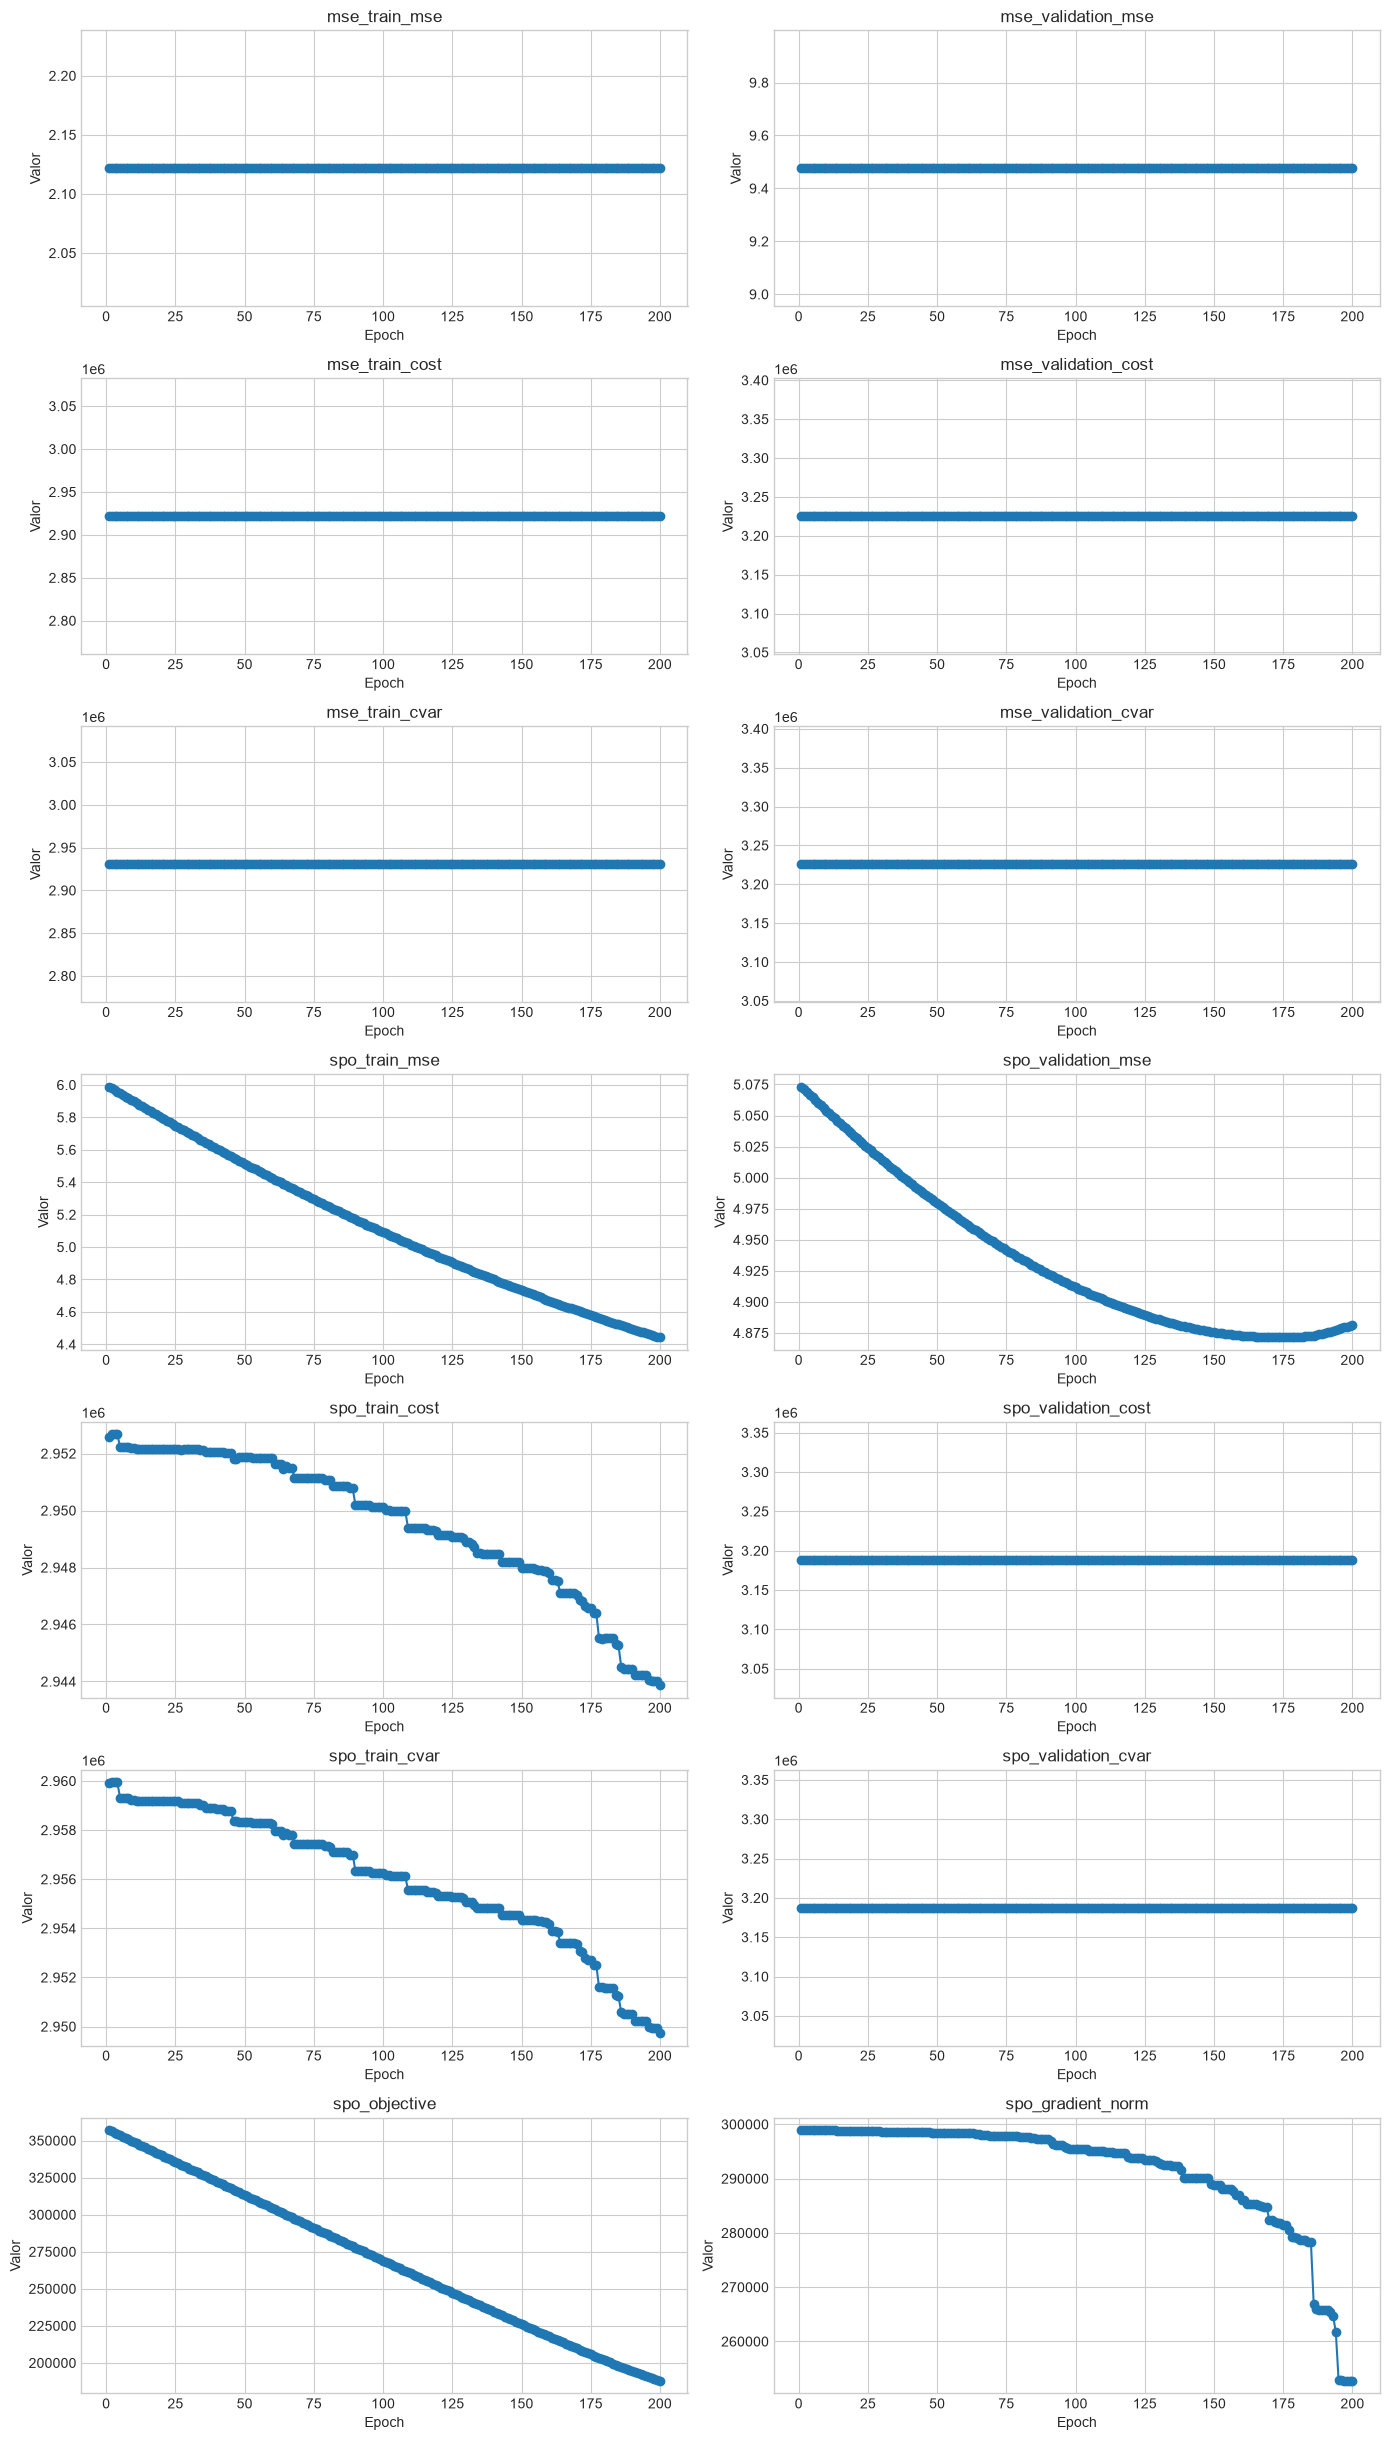

In [81]:
import re
import pandas as pd
import matplotlib.pyplot as plt

file_path='../energy_portfolio_training.log'
# Dicionário para armazenar as listas de métricas por época
epochs_data = {}

# Captura chaves flexíveis e valores com/sem aspas, listas ou números
pair_regex = re.compile(r'([a-zA-Z0-9_\.\-/\[\]\(\)]+)\s*=\s*("[^"]*"|\'[^\']*\'|\[[^\]]*\]|[^\s,]+)')

with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue

        matches = pair_regex.findall(line)
        if not matches:
            continue

        row = {}
        for k, v in matches:
            k_clean = k.lower().strip()
            v_clean = v.strip('"\'')

            # Tenta converter para int ou float
            try:
                if '.' in v_clean or 'e' in v_clean.lower():
                    val = float(v_clean)
                else:
                    val = int(v_clean)
            except ValueError:
                val = v_clean  # Mantém como texto se não for número

            row[k_clean] = val

        if 'epoch' in row:
            try:
                epoch_num = int(row['epoch'])
                if epoch_num not in epochs_data:
                    epochs_data[epoch_num] = {}
                epochs_data[epoch_num].update(row)
            except (ValueError, TypeError):
                continue

if not epochs_data:
    print("Nenhum dado com a chave 'epoch' foi encontrado no arquivo.")
    

# Converte para DataFrame
df = pd.DataFrame.from_dict(epochs_data, orient='index')
df.sort_index(inplace=True)

if 'epoch' not in df.columns:
    df['epoch'] = df.index

# Filtra colunas numéricas (exclui colunas de texto e a própria coluna 'epoch')
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
if 'epoch' in numeric_cols:
    numeric_cols.remove('epoch')

print(f"Épocas processadas: {len(df)}")
print(f"Colunas numéricas encontradas ({len(numeric_cols)}): {numeric_cols}")

if not numeric_cols:
    print("\nAtenção: Apenas a coluna 'epoch' foi identificada como numérica.")
    print("Amostra do conteúdo extraído para análise:")
    print(df.head())
    

# Configuração visual do Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Plot de todas as métricas em subplots individuais
num_metrics = len(numeric_cols)
cols_per_row = 2
rows = (num_metrics + cols_per_row - 1) // cols_per_row

fig, axes = plt.subplots(rows, cols_per_row, figsize=(14, 3.5 * rows))
if rows == 1 and cols_per_row == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    axes[idx].plot(df['epoch'], df[col], marker='o', linewidth=1.5)
    axes[idx].set_title(col, fontsize=12)
    axes[idx].set_xlabel('Epoch')
    axes[idx].set_ylabel('Valor')
    axes[idx].grid(True)

# Oculta eixos sobrantes
for idx in range(num_metrics, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()